# David Moya - Dataset 2

# 0. Imports, carga de datos y validaciones

### Imports

In [33]:
# Sistema y utilidades
import os
import glob
import pathlib
import warnings
import re
warnings.filterwarnings('ignore')

# Datos
import numpy as np
import pandas as pd

# Visualización - Matplotlib / Seaborn
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import seaborn as sns
from wordcloud import WordCloud

# Visualización - Plotly
import plotly.graph_objects as go
import plotly.express as px
import plotly.offline as pyo
import plotly.io as pio
from plotly.subplots import make_subplots

# Visualización - Plotnine
from plotnine import ggplot, aes, geom_histogram, geom_density, theme_minimal, labs, theme, element_text

# Machine Learning - Preprocesamiento
from sklearn.preprocessing import Normalizer, StandardScaler

# Machine Learning - Reducción dimensional
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

# Machine Learning - Clustering
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster

# Jupyter
from IPython.display import display, Markdown

# Estilo visual
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("tab10")

In [34]:
# Esto hace que los gráficos de Plotly se muestren directamente en el html del notebook
pyo.init_notebook_mode(connected=True)
pio.renderers.default = 'notebook_connected'

### Carga de datos

In [35]:
print("Directorio de trabajo actual:", os.getcwd())

data_path = pathlib.Path(os.getcwd()).parent / "inputsTextMining"
file_path = data_path / "inputsTextMining2.csv"

print("Archivo a cargar:", file_path)

df = pd.read_csv(file_path, encoding="latin-1", sep=",")
df.columns = [c.strip().lower() for c in df.columns]

# Validación de columnas esperadas
expected = {"id_documento", "palabra", "numvecpal"}
missing = expected - set(df.columns)
if missing:
    raise ValueError(f"Faltan columnas esperadas: {missing}. Columnas actuales: {df.columns.tolist()}")

print(f"\nDataFrame: {df.shape}")
print(f"Columnas: {df.columns.tolist()}")
print(f"Documentos únicos: {df['id_documento'].nunique()}")
print(f"Palabras únicas: {df['palabra'].nunique()}")

df.head(10)

Directorio de trabajo actual: c:\Users\dmoya\Master\Basic Machine Learning\Unsupervised_learning\MODELIZACIÓN_NO_SUPERVISADA_I\practica_text_mining\code
Archivo a cargar: c:\Users\dmoya\Master\Basic Machine Learning\Unsupervised_learning\MODELIZACIÓN_NO_SUPERVISADA_I\practica_text_mining\inputsTextMining\inputsTextMining2.csv

DataFrame: (211484, 3)
Columnas: ['id_documento', 'palabra', 'numvecpal']
Documentos únicos: 3000
Palabras únicas: 20529


,id_documento,palabra,numvecpal
0,1,ATLANTA,1
1,1,BACTERIA,1
2,1,CAPTAIN,1
3,1,CLEANER,1
4,1,COMMENT,1
5,1,CREATION,1
6,1,CRITIC,1
7,1,DELUCA,2
8,1,DEMAND,1
9,1,DORSAI,1


### Validaciones descriptivas y análisis del dataset

In [36]:
cols = ["id_documento", "palabra", "numvecpal"]

print("Shape df:", df.shape)
print("Columnas:", df.columns.tolist())

Shape df: (211484, 3)
Columnas: ['id_documento', 'palabra', 'numvecpal']



El dataset contiene **211.484 filas** y **3 columnas**: `id_documento`, 
`palabra` y `numvecpal`.

In [ ]:
# Tipos actuales
print("\nTipos (dtypes):")
print(df[cols].dtypes)


Tipos (dtypes):
id_documento    int64
palabra           str
numvecpal       int64
dtype: object


Las tres columnas tienen tipos correctos: `id_documento` y `numvecpal` 
son enteros (int64) y `palabra` es texto (str).

In [ ]:

# Nulos por columna
na_counts = df[cols].isna().sum().sort_values(ascending=False)
na_pct = (na_counts / len(df) * 100).round(4)
print("\nNulos por columna (count | %):")
print(pd.DataFrame({"na_count": na_counts, "na_pct": na_pct}))



Nulos por columna (count | %):
              na_count  na_pct
palabra              8  0.0038
id_documento         0  0.0000
numvecpal            0  0.0000


Se detectan **8 filas con valor NaN** en la columna `palabra` (0.004% 
del total). Las columnas `id_documento` y `numvecpal` no tienen ningún 
valor nulo. Estos 8 registros serán eliminados en el paso de limpieza.  

In [ ]:

# Estadísticas de numvecpal (sin forzar tipo)
print("\nnumvecpal - describe (puede salir raro si es object):")
display(df["numvecpal"].describe())



numvecpal - describe (puede salir raro si es object):


count    211484.000000
mean          1.466385
std           1.641573
min           1.000000
25%           1.000000
50%           1.000000
75%           1.000000
max         146.000000
Name: numvecpal, dtype: float64

La mayoría de palabras aparecen **1 sola vez** por documento (mediana=1, 
percentil 75=1). El máximo es 146, correspondiente a palabras muy 
repetidas en algún documento concreto. No hay valores no numéricos ni 
negativos.

In [ ]:

# Unicidad de documentos y vocabulario (ignorando NaN)
n_docs = df["id_documento"].nunique(dropna=True)
n_terms = df["palabra"].nunique(dropna=True)
print("\nCardinalidades:")
print("  Documentos únicos (dropna=True):", n_docs)
print("  Palabras únicas (dropna=True):", n_terms)



Cardinalidades:
  Documentos únicos (dropna=True): 3000
  Palabras únicas (dropna=True): 20529


El corpus contiene **3.000 documentos únicos** y un vocabulario de 
**20.529 palabras únicas**, lo que confirma que el dataset tiene 
exactamente los documentos esperados según el enunciado.

In [ ]:

# Duplicados por clave (id_documento, palabra)
dups_key = df.duplicated(["id_documento", "palabra"]).sum()
print("\nDuplicados por (id_documento, palabra):", dups_key)
if dups_key > 0:
    print("Muestra duplicados (primeras 20 filas duplicadas por clave):")
    display(df.loc[df.duplicated(["id_documento", "palabra"], keep=False), ["id_documento","palabra","numvecpal"]]
            .sort_values(["id_documento","palabra"]).head(20))



Duplicados por (id_documento, palabra): 0


No existe ningún par **(id_documento, palabra)** duplicado, lo que 
confirma que cada palabra aparece como máximo una vez por documento 
en el dataset original.

In [ ]:

# ¿Cada documento tiene al menos 1 fila?

doc_counts = df.dropna(subset=["id_documento"]).groupby("id_documento").size()
print("\nDistribución nº filas por documento (min/median/max):")
print("  min:", int(doc_counts.min()), " median:", float(doc_counts.median()), " max:", int(doc_counts.max()))
print("\nPercentiles nº filas por documento:")
print(doc_counts.quantile([0.01,0.05,0.10,0.25,0.50,0.75,0.90,0.95,0.99]).to_frame("n_filas").T)

display(Markdown("**Distribución del vocabulario en el corpus:**"))

# Creación del histograma base
fig = px.histogram(
    doc_counts, 
    nbins=50,                                                                  
    title='<b>Distribución de palabras únicas por documento</b>',              
    color_discrete_sequence=['#4C78A8']                                        
)

# Mejora estética de las barras
fig.update_traces(
    marker_line_width=1.2,                                                     
    marker_line_color='black',                                                 
    opacity=0.85                                                               
)

# Configuración del diseño general (layout)
fig.update_layout(
    template='plotly_white',                                                   
    showlegend=False,                                                         
    xaxis_title='<b>Número de palabras únicas</b>',                            
    yaxis_title='<b>Frecuencia (Nº de documentos)</b>',                        
    height=500,                                                                
    margin=dict(t=60, l=40, r=40, b=40)                                       
)

fig.show()



Distribución nº filas por documento (min/median/max):
  min: 7  median: 52.0  max: 1027

Percentiles nº filas por documento:
         0.01  0.05  0.10  0.25  0.50  0.75   0.90   0.95    0.99
n_filas  12.0  18.0  23.0  34.0  52.0  83.0  130.0  180.2  339.04


**Distribución del vocabulario en el corpus:**

Cada documento contiene entre **7 y 1.027 palabras únicas**, con una 
mediana de **52**.

In [ ]:

# Top 20 palabras más frecuentes por nº documentos donde aparecen (df_t preliminar)
df_tmp = df.dropna(subset=["id_documento","palabra"])
df_t_pre = df_tmp.groupby("palabra")["id_documento"].nunique().sort_values(ascending=False).head(20)
print("\nTop 20 palabras por nº de documentos donde aparecen (df_t preliminar):")
display(df_t_pre.to_frame("df_t"))

df_t_pre_plot = df_tmp.groupby("palabra")["id_documento"].nunique().sort_values(ascending=False).head(20).reset_index()
df_t_pre_plot.columns = ['palabra', 'n_documentos']

display(Markdown("**Top 20 palabras más frecuentes en el corpus:**"))

fig = px.bar(
    df_t_pre_plot,
    x='n_documentos', 
    y='palabra',
    orientation='h',
    title='<b>Top 20 palabras por número de documentos</b>',
    color_discrete_sequence=['#4C78A8']
)

fig.update_traces(
    marker_line_width=1.2,
    marker_line_color='black',
    opacity=0.85
)

fig.update_layout(
    template='plotly_white',
    yaxis={'categoryorder': 'total ascending'},
    xaxis_title='<b>Número de documentos</b>',
    yaxis_title='<b>Palabra</b>',
    height=600,
    margin=dict(t=60, l=80, r=40, b=40)
)

fig.show()


Top 20 palabras por nº de documentos donde aparecen (df_t preliminar):


,df_t
palabra,
UNIVERS,1278
DON,892
TIME,834
APPROV,813
SPACE,793
SCI,791
SYSTEM,654
NEW,646
YEAR,637


**Top 20 palabras más frecuentes en el corpus:**

Las palabras más frecuentes aparecen en hasta **1.278 documentos** 
(UNIVERS). Se observa que muchas son términos generales (TIME, NEW, 
GOOD, WORK) presentes en documentos de múltiples temáticas.

In [ ]:
# Estadísticas de longitud de palabras

df_tmp['longitud_palabra'] = df_tmp['palabra'].str.len()

display(Markdown("📏 **Estadísticas de longitud de palabras:**"))
display(df_tmp['longitud_palabra'].describe().to_frame().T)

fig = px.histogram(
    df_tmp,
    x='longitud_palabra',
    title='<b>Distribución de la longitud de las palabras</b>',
    color_discrete_sequence=['#4C78A8']
)

fig.update_traces(
    xbins=dict(size=1),
    marker_line_width=1.2,
    marker_line_color='black',
    opacity=0.85
)

fig.update_layout(
    template='plotly_white',
    showlegend=False,
    bargap=0,
    xaxis=dict(
        title='<b>Número de caracteres</b>',
        tickmode='linear',
        dtick=1
    ),
    yaxis_title='<b>Frecuencia (Nº de palabras)</b>',
    height=500,
    margin=dict(t=60, l=40, r=40, b=40)
)

fig.show()

📏 **Estadísticas de longitud de palabras:**

,count,mean,std,min,25%,50%,75%,max
longitud_palabra,211476.0,5.571044,1.712492,2.0,4.0,5.0,7.0,15.0


La longitud media de las palabras del corpus es de **5.57 caracteres**, 
con una mediana de **5**. El 75% de las palabras tienen 7 caracteres o 
menos, y la palabra más larga tiene 15 caracteres.

Hay que tener en cuenta dos factores que explican esta distribución:

- El corpus ya ha sido procesado con **stemming**, por lo que las palabras 
  están reducidas a su raíz (por ejemplo, CHRISTIAN en lugar de 
  CHRISTIANITY, o DISTRIBUT en lugar de DISTRIBUTION). Esto explica que 
  la longitud media sea relativamente baja y que no haya palabras muy largas.

- El dataset ya tiene las **stopwords eliminadas** según el enunciado, por 
  lo que no aparecen palabras muy cortas como preposiciones (IN, OF, AT) 
  o conjunciones (AND, OR, BUT). Esto explica que el mínimo sea de 
  **2 caracteres** y que haya muy pocas palabras por debajo de 4 caracteres 
  (percentil 25).

### Limpieza de Nas

In [51]:
df = (
    df.dropna(subset=["palabra"])
      .groupby(["id_documento", "palabra"], as_index=False)["numvecpal"].sum()
)

print("Shape tras limpieza:", df.shape)
print("Duplicados por (id_documento, palabra):", df.duplicated(["id_documento", "palabra"]).sum())
print("Nulos en palabra:", df["palabra"].isna().sum())

Shape tras limpieza: (211476, 3)
Duplicados por (id_documento, palabra): 0
Nulos en palabra: 0


# 1. Cálculo del TF-IDF

### 1.1. TF (Term Frequency)

El **TF (Term Frequency)** mide la frecuencia con la que aparece una palabra 
en un documento concreto. Se calcula como:

$$TF_{token, documento} = \frac{\text{nº veces que aparece el token en el documento}}{\text{nº total de tokens en el documento}}$$

El objetivo es **normalizar por la longitud del documento**: un documento 
largo tendrá naturalmente más repeticiones de cualquier palabra, por lo que 
dividir por el total de tokens permite comparar documentos de distinto tamaño 
de forma justa.

El TF por sí solo no es suficiente para medir la importancia de una palabra, 
ya que no tiene en cuenta si esa palabra es común en todos los documentos o 
exclusiva de unos pocos. Para eso se necesita el IDF, que se calculará en el 
paso siguiente.

In [52]:
# Total tokens por documento
tokens_por_doc = df.groupby('id_documento', as_index=False)['numvecpal'].sum() # Suma de frecuencias para obtener el total de tokens por documento
tokens_por_doc.columns = ['id_documento', 'total_tokens']                      # Renombrado de columnas para evitar conflictos en el cruce

# Merge + TF
df = df.merge(tokens_por_doc, on='id_documento', how='left')                   # Incorporación del total de tokens al dataframe original
df['tf'] = df['numvecpal'] / df['total_tokens']                                # Cálculo del Term Frequency (frecuencia relativa de la palabra)

# Validaciones mínimas
assert df['total_tokens'].isna().sum() == 0, "Hay filas sin total_tokens tras el merge"
assert (df['total_tokens'] > 0).all(), "Hay documentos con total_tokens <= 0"
assert (df['tf'] > 0).all() and (df['tf'] <= 1).all(), "TF fuera de rango (0,1]"

# Comprobación de integridad
tf_sum = df.groupby('id_documento')['tf'].sum()                                # Suma de TFs por documento (debe ser 1)
docs_con_error = (abs(tf_sum - 1) > 1e-9).sum()                                # Conteo de documentos con error, tolerando desvíos decimales

# Presentación del output
if docs_con_error > 0:
    display(Markdown(f"⚠️ **Aviso:** Hay **{docs_con_error}** documentos cuya suma de TF no es exactamente 1."))
else:
    display(Markdown("✅ **Validación matemática exitosa:** La suma del TF en todos los documentos es igual a 1."))

display(df[['id_documento', 'palabra', 'numvecpal', 'total_tokens', 'tf']].head(10)) 

✅ **Validación matemática exitosa:** La suma del TF en todos los documentos es igual a 1.

,id_documento,palabra,numvecpal,total_tokens,tf
0,1,ATLANTA,1,44,0.022727
1,1,BACTERIA,1,44,0.022727
2,1,CAPTAIN,1,44,0.022727
3,1,CLEANER,1,44,0.022727
4,1,COMMENT,1,44,0.022727
5,1,CREATION,1,44,0.022727
6,1,CRITIC,1,44,0.022727
7,1,DELUCA,2,44,0.045455
8,1,DEMAND,1,44,0.022727
9,1,DORSAI,1,44,0.022727


La validación confirma que **todos los documentos tienen suma de TF igual a 1**, 
lo que significa que el cálculo es correcto. 

### 1.2. IDF (Inverse Document Frequency) y TF-IDF

El **IDF (Inverse Document Frequency)** penaliza las palabras que aparecen 
en muchos documentos, ya que aportan poca información discriminatoria. 
Se calcula como:

$$IDF_{token} = \log\left(\frac{N}{1 + df_t}\right)$$

donde:
- $N$ = número total de documentos (3.000)
- $df_t$ = número de documentos en los que aparece el término $t$
- El $+1$ en el denominador evita divisiones por cero

El **TF-IDF** combina ambas métricas:

$$TF\text{-}IDF = TF \times IDF$$

Una palabra tendrá un TF-IDF alto si aparece **frecuentemente en un documento 
concreto** pero **raramente en el resto del corpus**. Esto permite identificar 
las palabras más representativas de cada documento.

In [53]:
# Total de documentos (N)
N = df['id_documento'].nunique()                                               # Cálculo del número total de documentos únicos en el corpus

# Document Frequency
doc_freq = df.groupby('palabra')['id_documento'].nunique().reset_index()       # Conteo de en cuántos documentos distintos aparece cada palabra
doc_freq.columns = ['palabra', 'DF']                                           # Renombrado de columnas para evitar conflictos

# IDF
doc_freq['IDF'] = np.log(N / (1 + doc_freq['DF']))                             # Cálculo del Inverse Document Frequency (penaliza términos muy comunes)

# Merge y cálculo de TF-IDF
df = df.merge(doc_freq[['palabra', 'IDF']], on='palabra', how='left')          # Incorporación del valor IDF al dataframe principal
df['TF_IDF'] = df['tf'] * df['IDF']                                            # Cálculo final del peso multiplicando ambas métricas

# Presentación del output
display(Markdown(f"🔹 **N (total de documentos):** {N}"))

display(Markdown("📊 **Estadísticas globales de TF-IDF:**"))
display(df['TF_IDF'].describe().to_frame().T)                                  # Conversión a dataframe y transposición para una lectura más limpia

display(Markdown("🔍 **Muestra de resultados:**"))
display(df[['id_documento', 'palabra', 'tf', 'IDF', 'TF_IDF']].head(10))       # Renderizado de los primeros 10 registros en formato tabla

🔹 **N (total de documentos):** 3000

📊 **Estadísticas globales de TF-IDF:**

,count,mean,std,min,25%,50%,75%,max
TF_IDF,211476.0,0.055998,0.065985,0.000493,0.018279,0.036364,0.068465,1.462644


🔍 **Muestra de resultados:**

,id_documento,palabra,tf,IDF,TF_IDF
0,1,ATLANTA,0.022727,3.879233,0.088164
1,1,BACTERIA,0.022727,5.703782,0.129631
2,1,CAPTAIN,0.022727,6.060457,0.137738
3,1,CLEANER,0.022727,6.060457,0.137738
4,1,COMMENT,0.022727,2.764621,0.062832
5,1,CREATION,0.022727,4.480007,0.101818
6,1,CRITIC,0.022727,3.801675,0.086402
7,1,DELUCA,0.045455,6.214608,0.282482
8,1,DEMAND,0.022727,4.245167,0.096481
9,1,DORSAI,0.022727,6.907755,0.156994



El corpus contiene **211.476 pares (documento, palabra)** con un TF-IDF 
medio de 0.056. Respecto a las estadísticas del TF-IDF, se comprueba que el **75% de los valores están por debajo de 0.068**, lo que indica que 
la mayoría de palabras tienen una importancia moderada-baja.

Un término con TF-IDF alto es más **representativo** de ese documento 
concreto: aparece con frecuencia en él pero es raro en el resto del corpus. 
Por ejemplo, en el documento 1, DORSAI (TF-IDF = 0.157) es más 
representativo que COMMENT (TF-IDF = 0.063), ya que COMMENT es una palabra 
común en muchos documentos mientras que DORSAI es casi exclusiva de este.

### 1.3. Validación del TF-IDF


Antes de continuar, se realizan una serie de checks para confirmar que 
el cálculo del TF-IDF es correcto:

In [54]:
# Preparación de métricas de control
shape_df = df.shape                                                            # Obtención de dimensiones del dataframe
stats_tfidf = df['TF_IDF'].describe(percentiles=[.10,.25,.50,.75,.90,.95,.99]) # Cálculo de estadísticas con percentiles personalizados

# Creación de tabla resumen para comprobaciones
resumen_checks = pd.DataFrame({
    'Métrica': [
        'Valores TF-IDF < 0', 
        'Valores TF-IDF == 0', 
        'Valores TF-IDF > 0', 
        'IDF mínimo', 
        'IDF máximo', 
        'Palabras con IDF < 0'
    ],
    'Resultado': [
        (df['TF_IDF'] < 0).sum(),                                              # Conteo de TF-IDF negativos
        (df['TF_IDF'] == 0).sum(),                                             # Conteo de TF-IDF nulos
        (df['TF_IDF'] > 0).sum(),                                              # Conteo de TF-IDF positivos
        round(df['IDF'].min(), 4),                                             # Extracción del IDF mínimo (redondeado)
        round(df['IDF'].max(), 4),                                             # Extracción del IDF máximo (redondeado)
        (df['IDF'] < 0).sum()                                                  # Conteo de IDF negativos
    ]
})

# Presentación del output
display(Markdown(f"🔹 **Dimensiones del DataFrame:** {shape_df[0]} filas y {shape_df[1]} columnas"))

display(Markdown("📋 **Checks básicos de TF-IDF e IDF:**"))
display(resumen_checks)                                                        

display(Markdown("📈 **Estadísticas detalladas de TF-IDF:**"))
display(stats_tfidf.to_frame().T)                                             

🔹 **Dimensiones del DataFrame:** 211476 filas y 7 columnas

📋 **Checks básicos de TF-IDF e IDF:**

,Métrica,Resultado
0,Valores TF-IDF < 0,0.0000
1,Valores TF-IDF == 0,0.0000
2,Valores TF-IDF > 0,211476.0000
3,IDF mínimo,0.8525
4,IDF máximo,7.3132
5,Palabras con IDF < 0,0.0000


📈 **Estadísticas detalladas de TF-IDF:**

,count,mean,std,min,10%,25%,50%,75%,90%,95%,99%,max
TF_IDF,211476.0,0.055998,0.065985,0.000493,0.008974,0.018279,0.036364,0.068465,0.120811,0.171465,0.328941,1.462644


- **Todos los valores son positivos**: no hay TF-IDF negativos ni ceros, 
  lo que confirma que el cálculo es correcto.
- **IDF mínimo de 0.85**: ninguna palabra aparece en todos los documentos, 
  por lo que todos los términos aportan algo de información.
- **IDF máximo de 7.31**: hay palabras muy exclusivas de documentos concretos, 
  lo que indica que el corpus tiene vocabulario especializado por temáticas.
- **Sin palabras con IDF negativo**: la fórmula utilizada garantiza IDF ≥ 0 
  en todos los casos.

### 1.4. Distribución valores IDF

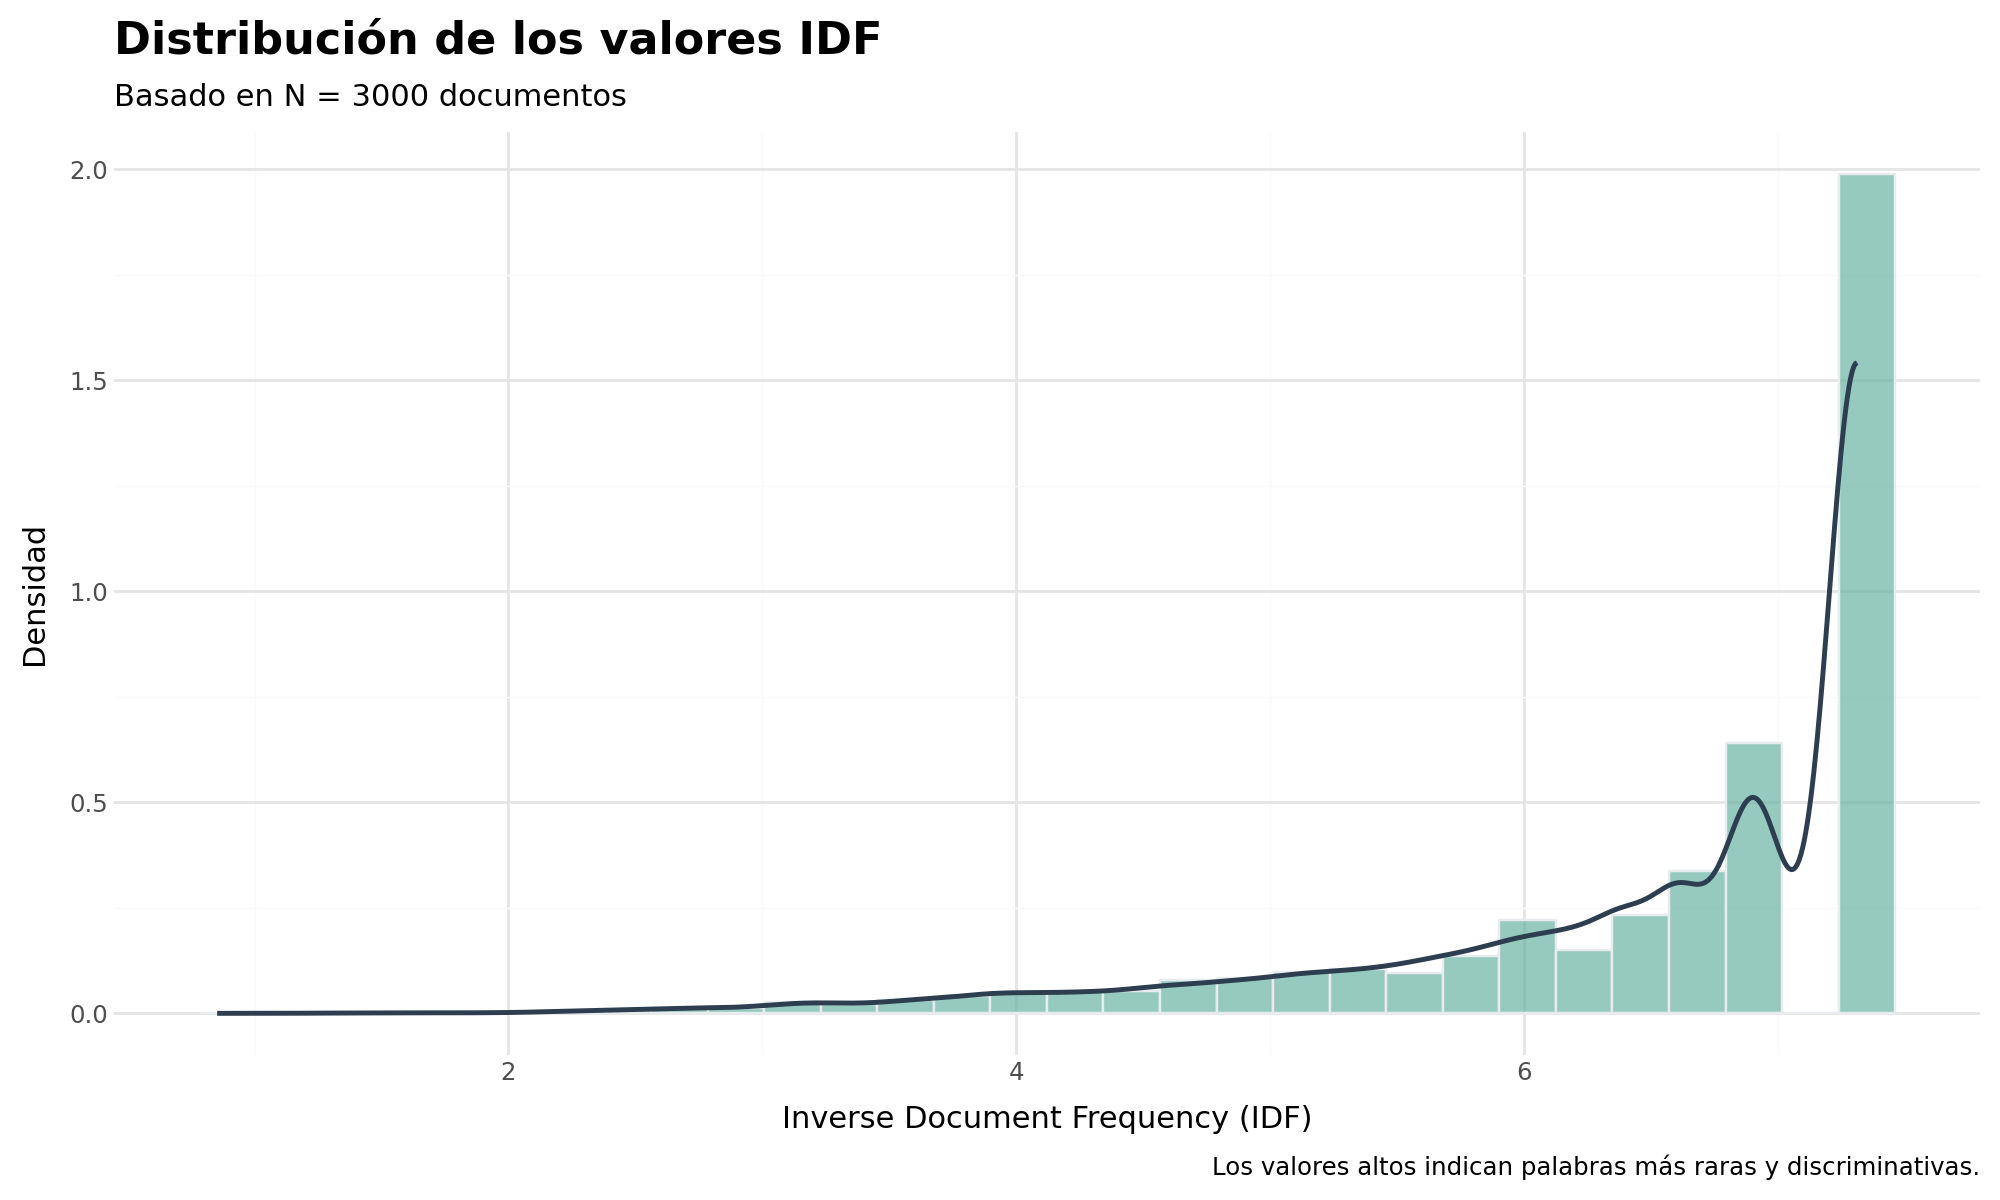

In [55]:
# 1. Preparar los datos (usamos doc_freq porque tiene un valor único por palabra)
# Esto evita sesgos si una palabra se repite mucho en el dataframe principal 'df'
df_viz = doc_freq.copy()

# 2. Crear la visualización
plot_idf = (
    ggplot(df_viz, aes(x='IDF'))
    + geom_histogram(aes(y='stat(density)'), bins=30, fill="#69b3a2", color="#e9ecef", alpha=0.7)
    + geom_density(color="#2c3e50", size=1)
    + theme_minimal()
    + labs(
        title="Distribución de los valores IDF",
        subtitle=f"Basado en N = {N} documentos",
        x="Inverse Document Frequency (IDF)",
        y="Densidad",
        caption="Los valores altos indican palabras más raras y discriminativas."
    )
    + theme(
        plot_title=element_text(size=16, face="bold"),
        figure_size=(10, 6)
    )
)

plot_idf

# 2. Transition Point

El Transition Point es un punto de corte que se basa en la importancia que tiene cada palabra en todo el corpus.

## 2.1. Cálculo de la suma agregada de TF-IDF por término

$SUM\_TFIDF(t) = \sum_{d} TFIDF(d,t)$

Indica cuánto peso total tiene una palabra en todo el conjunto de documentos.

- Si una palabra aparece mucho y es discriminativa tendrá una suma agregada alta 
- Si una palabra aparece poco o no es discriminativa tendrá una suma agregada alta 

Permite detectar las palabras más importantes de todo el conjunto de datos. Permite evitar palabras raras que aparecen en un solo documento, ruido, términos demasiado específicos, etc.

In [56]:
# SUM_TF_IDF: suma del TF-IDF de cada palabra a lo largo de todos los documentos
sum_tfidf = df.groupby('palabra')['TF_IDF'].sum().reset_index()
sum_tfidf.columns = ['palabra', 'SUM_TF_IDF']

Este cálculo le da a cada palabra un `SUM_TF_IDF`, por lo que ahora hay que decidir cuáles se conservan y cuáles no se tienen en cuenta, y esto se resuelve con la elección del **percentil**, que permite seleccionar las SUM_TF_IDF más altas.

### Distribución del SUM_TF_IDF por palabra

Para decidir qué palabras son suficientemente relevantes para el análisis, 
se calcula el **SUM_TF_IDF** de cada palabra: la suma de sus valores TF-IDF 
a lo largo de todos los documentos del corpus. Una palabra con SUM_TF_IDF 
alto aparece con frecuencia y de forma relevante en muchos documentos.

Los siguientes gráficos muestran cómo se distribuye esta métrica entre las 
palabras del vocabulario.

In [57]:
sorted_vals = sum_tfidf['SUM_TF_IDF'].sort_values(ascending=False).reset_index(drop=True)

fig = make_subplots(
    rows=1, cols=2, 
    subplot_titles=(
        "SUM_TF_IDF ordenado (mayor a menor)", 
        "SUM_TF_IDF ordenado (escala log)"
    ),
    horizontal_spacing=0.08 
)

# 1. Curva ordenada
fig.add_trace(
    go.Scatter(
        x=sorted_vals.index, 
        y=sorted_vals.values, 
        mode='lines',
        line=dict(color='steelblue', width=2),
        name="Ranking",
        hovertemplate="<b>Ranking:</b> %{x}<br><b>SUM_TF_IDF:</b> %{y:,.2f}<extra></extra>"
    ),
    row=1, col=1  
)

# 2. Ranking log
fig.add_trace(
    go.Scatter(
        x=sorted_vals.index, 
        y=sorted_vals.values, 
        mode='lines',
        line=dict(color='steelblue', width=2),
        name="Ranking (Log)",
        hovertemplate="<b>Ranking:</b> %{x}<br><b>SUM_TF_IDF:</b> %{y:,.2f}<extra></extra>"
    ),
    row=1, col=2  # ← col=2
)

fig.update_layout(
    template='plotly_white',
    height=500,
    showlegend=False,
    margin=dict(t=80, b=40, l=40, r=40)
)

fig.update_xaxes(title_text="Ranking de palabras", row=1, col=1)
fig.update_xaxes(title_text="Ranking palabras", row=1, col=2)
fig.update_yaxes(title_text="SUM_TF_IDF", row=1, col=1)
fig.update_yaxes(title_text="SUM_TF_IDF (log)", type="log", row=1, col=2)

fig.show()

Ambos gráficos confirman que la distribución del SUM_TF_IDF sigue una 
**ley de potencia**: un pequeño número de palabras concentra la mayor parte 
de la relevancia, mientras que la gran mayoría tienen un SUM_TF_IDF muy bajo.

- En el gráfico izquierdo se aprecia el **codo**: las primeras ~1.000 palabras 
  tienen SUM_TF_IDF claramente por encima del resto, y a partir de ahí la 
  curva cae rápidamente hacia cero.
- El gráfico en escala logarítmica confirma que la caída es prácticamente 
  lineal en log, lo que es característico de distribuciones de tipo ley de 
  potencia en vocabularios naturales.

Esto justifica aplicar un **transition point** en el percentil 95, 
quedándonos únicamente con las ~1.027 palabras más relevantes del corpus 
y descartando el 95% del vocabulario, que aporta muy poca información.

## 2.2. Elección de percentil

En este caso se elige en percentil 95.

In [58]:

# Transition point: percentil 90
percentil = 0.95
top = 1- percentil


## 2.3. Cálculo del transition point

Cálcula el valor numérico que separa el 95% inferior del 5% superior

In [59]:
transition_point = sum_tfidf['SUM_TF_IDF'].quantile(percentil)
print(f"\nTransition point (percentil {percentil}): {transition_point:.4f}")
print(f"Palabras totales antes del filtro: {sum_tfidf.shape[0]}")



Transition point (percentil 0.95): 2.6108
Palabras totales antes del filtro: 20529


- El 95% de las palabras tiene un SUM_TF_IDF menor o igual que 2.6108.
- Solo el 5% de las palabras tiene un SUM_TF_IDF mayor o igual que 2.6108. Este número es el **valor de corte**

## 2.4. Se seleccionan las palabras relevantes

Crea una lista solo con las palabras más importantes.

In [60]:
palabras_relevantes = sum_tfidf[sum_tfidf['SUM_TF_IDF'] >= transition_point]['palabra']

display(Markdown(f"**Palabras seleccionadas (top {top*100:.1f}%):** {len(palabras_relevantes)}"))
display(Markdown("**Ejemplo de palabras seleccionadas:**"))
display(Markdown(f"> {', '.join(palabras_relevantes.head(20).astype(str).tolist())}"))

**Palabras seleccionadas (top 5.0%):** 1027

**Ejemplo de palabras seleccionadas:**

> ABIL, ABSOLUT, ACCELER, ACCEPT, ACCESS, ACCOUNT, ACT, ACTION, ACTIV, ACTUAL, ADAM, ADAPTEC, ADDRESS, ADMIN, ADMINISTR, ADVANC, ADVERTIS, ADVIC, AGRE, ALAN

## 2.5. Filtrar el dataframe principal

In [61]:
# Filtrar el DataFrame principal
df_filtrado = df[df['palabra'].isin(palabras_relevantes)].copy()               # Creación de nuevo dataframe conservando solo palabras relevantes

# Cálculo de métricas de impacto
reduccion_dim = 1 - (len(palabras_relevantes) / sum_tfidf.shape[0])            # Cálculo de la reducción dimensional del vocabulario
docs_unicos = df_filtrado['id_documento'].nunique()                            # Conteo de documentos que sobreviven al filtro

# Creación de tabla resumen del filtrado
resumen_filtro = pd.DataFrame({
    'Métrica': [
        'Registros antes del filtro',
        'Registros después del filtro',
        'Reducción dimensional del vocabulario',
        'Documentos únicos tras filtro'
    ],
    'Valor': [
        f"{df.shape[0]:,}",                                                    # Formateo con separador de miles
        f"{df_filtrado.shape[0]:,}",                                           # Formateo con separador de miles
        f"{reduccion_dim * 100:.2f}%",                                         # Formateo como porcentaje 
        f"{docs_unicos:,}"                                                     
    ]
})

# Presentación del output
display(Markdown("**Impacto del filtrado por relevancia:**"))
display(resumen_filtro)                                                        

display(Markdown("**Estadísticas de SUM_TF_IDF original:**"))
display(sum_tfidf['SUM_TF_IDF'].describe().to_frame().T)                       

**Impacto del filtrado por relevancia:**

,Métrica,Valor
0,Registros antes del filtro,"211,476"
1,Registros después del filtro,"115,393"
2,Reducción dimensional del vocabulario,95.00%
3,Documentos únicos tras filtro,"3,000"


**Estadísticas de SUM_TF_IDF original:**

,count,mean,std,min,25%,50%,75%,max
SUM_TF_IDF,20529.0,0.576853,1.401954,0.002942,0.048755,0.149921,0.461029,32.32128


- Después de eliminar palabras poco importantes, se pasa de 211476 filas a 115393, lo que significa que se han eliminado muchas ocurrencias de palabras irrelevantes.
- De las 20529 palabras únicas, se conservan las 1026 palabras únicas más importantes, es decir, el vocabulario se reduce en un 95%, lo que mejorará el PCA y el clustering.

# 3. Pivotado

Hasta este punto, los datos están en **formato largo**: cada fila representa 
un par (documento, palabra) con su valor TF-IDF asociado.

Ejemplo:

| id_documento | palabra  | TF_IDF |
|--------------|----------|--------|
| 1            | ATLANTA  | 0.088  |
| 1            | COMMENT  | 0.063  |
| 2            | SPORT    | 0.045  |
| 2            | ATLANTA  | 0.021  |

Para poder aplicar algoritmos de Machine Learning (PCA, K-Means, etc.), 
necesitamos transformar esta tabla a **formato matricial**: una fila por 
documento y una columna por palabra. A esto se le llama **pivotar**.

El resultado sería:

| id_documento | ATLANTA | COMMENT | SPORT |
|--------------|---------|---------|-------|
| 1            | 0.088   | 0.063   | 0.000 |
| 2            | 0.021   | 0.000   | 0.045 |

Los ceros representan palabras que **no aparecen** en ese documento.

In [62]:
# Creación de la matriz documento-término
matriz = df_filtrado.pivot_table(
    index='id_documento',                                              # Asignación de documentos a las filas
    columns='palabra',                                                 # Asignación de palabras a las columnas
    values='TF_IDF',                                                   # Uso del peso TF-IDF como valores de la matriz
    aggfunc='sum',                                                     # Suma de pesos si una palabra se repite en el documento
    fill_value=0                                                       
)

# Cálculo de métricas de la matriz
n_docs, n_palabras = matriz.shape                                      # Extracción de dimensiones (filas y columnas)
densidad = (matriz > 0).sum().sum() / (n_docs * n_palabras) * 100      # Cálculo del porcentaje de celdas distintas de cero

# Creación de tabla resumen
resumen_matriz = pd.DataFrame({
    'Métrica': [
        'Documentos (filas)', 
        'Palabras (columnas)', 
        'Densidad de la matriz'
    ],
    'Valor': [
        f"{n_docs:,}",                                                 # Formateo con separador de miles
        f"{n_palabras:,}",                                             # Formateo con separador de miles
        f"{densidad:.2f}%"                                             # Formateo como porcentaje con dos decimales
    ]
})

# Presentación del output
display(Markdown("**Resumen de la Matriz Documento-Término (TF-IDF):**"))
display(resumen_matriz)                                                

**Resumen de la Matriz Documento-Término (TF-IDF):**

,Métrica,Valor
0,Documentos (filas),"3,000"
1,Palabras (columnas),"1,027"
2,Densidad de la matriz,3.75%


Esto genera una matriz muy dispersa (*sparse*): en nuestro caso, solo el 
**3.75% de los valores son distintos de cero**, es decir, el 96.25% de la matriz son ceros.

Esta matriz tiene forma **(3000 documentos × 1027 palabras)**, que será 
la entrada para los pasos siguientes de normalización y reducción dimensional.

Espacio de 1027 dimensiones. Cada palabra es un eje y cada documento tiene una coordenada en ese espacio. Esto genera un problema de dimensionalidad ya que en un espacio de muchas dimensiones las distancias tienden a parecerse, se introduce mucho ruido, etc. Por ello se usa el PCA como método de reducción de dimensionalidad, que permite comprimir el espacio sin perder demasiada información. 

# 4. Normalización

Una vez pivotada la matriz, cada fila representa un documento como un 
vector numérico de 2053 dimensiones (una por palabra). Sin embargo, 
los valores TF-IDF de cada fila no son comparables directamente entre 
documentos, ya que documentos más largos tienden a tener valores más altos.

Para corregir esto, **normalizamos cada fila** de forma que todos los 
documentos queden en una escala comparable antes de aplicar PCA y clustering.


### 4.1. ¿Qué tipo de normalización usar?

Existen dos opciones principales:

- **Normalización L1**: divide cada valor por la suma de todos los valores 
  de la fila. El resultado es que los valores de cada fila suman 1, 
  interpretándose como proporciones. Es lo que sugiere el enunciado.

- **Normalización L2**: divide cada valor por la norma euclidiana de la fila 
  (raíz cuadrada de la suma de los cuadrados). El resultado es que cada 
  fila tiene norma 1.

### 4.2. Decisión

Se probó primero con **L1** (como indica el enunciado), pero los resultados 
del clustering fueron pobres: clusters desbalanceados y poco interpretables. 

Tras la experimentación, se optó por **L2**, que produce vectores unitarios 
en el espacio euclidiano y es más adecuada cuando posteriormente se aplica 
PCA seguido de K-Means, ya que este algoritmo trabaja con distancias 
euclidianas.

In [63]:
normalizer = Normalizer(norm="l2")
X = normalizer.fit_transform(matriz)  # numpy array

print("X_l2 (matriz normalizada L1):", X.shape)

X_l2 (matriz normalizada L1): (3000, 1027)


In [64]:
# Validaciones de la matriz X
n_filas, n_cols = X.shape                                                      # Extracción de dimensiones de la matriz
suma_filas = pd.Series(X.sum(axis=1))                                          # Suma de valores por fila para verificar normalización
valores_negativos = (X < 0).sum()                                              # Conteo de celdas con valores negativos
valores_nan = np.isnan(X).sum()                                                # Conteo de celdas con valores nulos (NaN)

# Creación de tabla resumen
resumen_X = pd.DataFrame({
    'Métrica': [
        'Filas (documentos)', 
        'Columnas (características)', 
        'Valores negativos', 
        'Valores NaN'
    ],
    'Valor': [
        f"{n_filas:,}",                                                        # Formateo con separador de miles
        f"{n_cols:,}",                                                         # Formateo con separador de miles
        valores_negativos,                                                     # Inserción del conteo de negativos
        valores_nan                                                            # Inserción del conteo de nulos
    ]
})

# Presentación del output
display(Markdown(" **Controles de calidad de la matriz X:**"))
display(resumen_X)                                                             

display(Markdown("**Estadísticas de la norma euclidiana por filas (esperado ~1 para L2):**"))
display(pd.Series(np.linalg.norm(X, axis=1)).describe().to_frame().T)                                    

 **Controles de calidad de la matriz X:**

,Métrica,Valor
0,Filas (documentos),"3,000"
1,Columnas (características),"1,027"
2,Valores negativos,0
3,Valores NaN,0


**Estadísticas de la norma euclidiana por filas (esperado ~1 para L2):**

,count,mean,std,min,25%,50%,75%,max
0,3000.0,1.0,8.292204e-17,1.0,1.0,1.0,1.0,1.0


Tras la normalización L2, la norma euclidiana de cada fila es exactamente 1, confirmando que todos los documentos están en la misma escala.

# 5. PCA

PCA reduce dimensionalidad conservando la mayor variabilidad posible. El PCA gira los ejes y encuentra la dirección en la que hay más variación (PC1 - Primera componente principal) y después encuentra la segunda dirección perpendicular con más variación (PC2 - Segunda componente principal). 

## 5.1. Eliminar columnas constantes

Si una palabra tiene varianza 0 significa que ale lo mismo en todos los documentos, por lo que no aporta información y el PCA no puede trabajar bien con ella.

In [65]:

std_cols = X.std(axis=0)
X = X[:, std_cols > 0]
print("Matriz tras quitar columnas constantes:", X.shape)

Matriz tras quitar columnas constantes: (3000, 1027)


Tras la normalización L2 y el filtrado por transition point, 
se comprueba que no quedan columnas constantes.

## 5.2. Análisis exploratorio de componentes principales (PCA diagnóstico)

PCA completo para diagnosticar la varianza explicada por cada componente y las componentes necesarias para explicar el 70%, 80% y 90% de la varianza.

### 5.2.1. Componentes

Un **componente principal** es una nueva variable artificial creada como 
combinación lineal de todas las palabras originales. Por ejemplo:

$$PC1 = 0.3 \cdot GAME + 0.2 \cdot TEAM + 0.1 \cdot PLAYER - 0.05 \cdot GOD - 0.03 \cdot SPACE...$$

Cada componente captura un **patrón de co-ocurrencia** entre palabras: 
palabras que tienden a aparecer juntas en los mismos documentos tendrán 
coeficientes similares en el mismo componente.

El PCA ordena los componentes de mayor a menor varianza explicada:
- **PC1** es la dirección en la que los documentos varían más entre sí.
- **PC2** es la segunda dirección de máxima varianza, perpendicular a PC1.
- Y así sucesivamente.

En nuestro caso, partimos de **1.027 palabras** (dimensiones originales) 
y el PCA nos permite representar cada documento como una combinación de 
**1.027 componentes**. El objetivo del análisis exploratorio es determinar 
cuántos de esos componentes son suficientes para capturar la estructura 
temática del corpus.

En esta celda, se calculan todos los componentes posibles, es decir, si 
tenemos 1027 palabras tendremos 1027 componentes posibles.

In [66]:
pca_full = PCA(random_state=42)
X_pca_full = pca_full.fit_transform(X)

### 5.2.2. Varianza explicada

In [67]:

explained_variance = pca_full.explained_variance_     # Varianza explicada por cada componente         
explained_ratio = pca_full.explained_variance_ratio_  # Ratio de varianza explicada por cada componente

### 5.2.3. Varianza acumulada


Responde a cuantos componentes se necesitan para explicar un tanto por ciento de la información.

Ej:

| Componente | Varianza acumulada |
| ---------- | ------------------ |
| 1          | 0.005              |
| 2          | 0.010              |
| 3          | 0.014              |
| ...        | ...                |


In [68]:
cumpro = np.cumsum(explained_ratio)

### 5.2.4. Resumen PCA

In [69]:
print("\n=== RESUMEN PCA ===")
print("N componentes:", len(explained_ratio))
print("Varianza acumulada (primeras 10):", np.round(cumpro[:10], 4))


=== RESUMEN PCA ===
N componentes: 1027
Varianza acumulada (primeras 10): [0.0156 0.0297 0.0432 0.0518 0.0584 0.0649 0.0708 0.0764 0.0819 0.0874]


In [70]:
print("Varianza acumulada en 50 componentes:", round(cumpro[49], 4))
print("Varianza acumulada en 100 componentes:", round(cumpro[99], 4))
print("Varianza acumulada en 200 componentes:", round(cumpro[199], 4))
print("Componentes necesarias para 80% varianza:", np.argmax(cumpro >= 0.80) + 1)
print("Componentes necesarias para 90% varianza:", np.argmax(cumpro >= 0.90) + 1)

Varianza acumulada en 50 componentes: 0.2381
Varianza acumulada en 100 componentes: 0.3644
Varianza acumulada en 200 componentes: 0.5438
Componentes necesarias para 80% varianza: 445
Componentes necesarias para 90% varianza: 616


Los resultados muestran que la varianza está muy distribuida entre todas las 
componentes, sin un codo claro. Esto es **normal en matrices TF-IDF sparse**: 
el vocabulario es amplio y ninguna palabra domina claramente sobre las demás.

### 5.2.5. Criterio de varianza acumulada

In [71]:
import plotly.graph_objects as go
import pandas as pd
import numpy as np
from IPython.display import display

# --- 1) Gráfico de Varianza Acumulada ---
fig1 = go.Figure()

fig1.add_trace(go.Scatter(
    y=cumpro, 
    mode='lines+markers', 
    name='Acumulada'
))

fig1.add_hline(y=0.70, line_dash="dash", line_color="purple", annotation_text="70%")
fig1.add_hline(y=0.80, line_dash="dash", line_color="green", annotation_text="80%")
fig1.add_hline(y=0.90, line_dash="dash", line_color="orange", annotation_text="90%")

fig1.update_layout(
    title_text="Diagnóstico PCA - Varianza acumulada explicada",
    xaxis_title="Número de Componente Principal (PC #)",
    yaxis_title="Varianza acumulada explicada",
    height=500,
    showlegend=False
)

# Mostramos el gráfico
fig1.show()

# --- 2) Tabla bonita de Umbrales ---
umbrales = [0.70, 0.75, 0.80, 0.85, 0.90]
datos_tabla = []

# Calculamos las componentes y las guardamos en una lista
for umbral in umbrales:
    n = int(np.argmax(cumpro >= umbral) + 1)
    datos_tabla.append({
        "Umbral de Varianza": f"{int(umbral * 100)}%", 
        "Componentes Necesarios": n
    })

# Convertimos la lista en un DataFrame de pandas
df_umbrales = pd.DataFrame(datos_tabla)

# Usamos display para que Jupyter lo dibuje como una tabla estilizada
display(df_umbrales)

,Umbral de Varianza,Componentes Necesarios
0,70%,328
1,75%,382
2,80%,445
3,85%,521
4,90%,616


El gráfico de varianza acumulada muestra que la información se distribuye de forma progresiva entre un gran número de componentes, sin un punto de inflexión claramente definido. Para explicar aproximadamente el 70% de la varianza son necesarias alrededor de 300 componentes, mientras que para alcanzar el 80% se requieren más de 400 componentes.

Dado que en problemas de text mining la varianza suele estar ampliamente distribuida, se opta por conservar un número de componentes que capture entre el 70% y el 80% de la información total, equilibrando compresión y retención de información.

### 5.2.6. Varianza individual para las primeras 50 componentes

In [72]:

# --- 5) Varianza individual primeras 50 en % ---
top = min(50, len(explained_ratio))
fig2 = px.bar(
    x=range(1, top + 1), 
    y=explained_ratio[:top] * 100,
    labels={'x': 'Componente principal', 'y': '% Varianza explicada'},
    title=f"Varianza explicada por componente (primeras {top})"
)
fig2.show()

El gráfico muestra la varianza explicada por cada una de las primeras 50 
componentes principales. La primera componente explica aproximadamente el 
**1.56%** de la varianza, y la curva desciende de forma suave y progresiva 
sin un codo claro.

Se aprecia una caída más pronunciada a partir de la **4ª componente** 
(de ~1.35% baja a ~0.85%), lo que sugiere un codo débil. Este punto es 
consistente con las 4 temáticas identificadas posteriormente en el clustering.

A partir de ahí, la curva se aplana progresivamente sin un codo adicional 
claro, confirmando que **no hay unas pocas componentes que dominen 
claramente** sobre las demás. La información está repartida de forma 
bastante uniforme entre todas ellas, lo cual es típico de matrices 
TF-IDF sparse con vocabularios amplios..

# 6. PCA reducido para clustering

Este es el PCA real que se usará para el clustering. Antes cada documento era un vector de palabras, ahora cada documento es una combinación de patrones, es decir, cada componente principal es una combinación lineal de palabras.

## 6.1. Elección del número de componentes

Aplicando el criterio de la varianza acumulada, para explicar el 70% de la varianza explicada se necesita aproximadamente 330 componentes.

In [73]:
n_components_pca = 330

Se pasarán de 1027 dimensiones a 330. 

## 6.2. Aplicar PCA reducido

Aprende las direcciones principales. Proyecta cada documento en esas 300 direcciones.

In [74]:
pca = PCA(n_components=n_components_pca, random_state=42)
X_pca = pca.fit_transform(X)

print("Shape X_pca:", X_pca.shape)
print(f"Varianza explicada acumulada con {n_components_pca} componentes: "
      f"{pca.explained_variance_ratio_.sum()*100:.2f}%")

Shape X_pca: (3000, 330)
Varianza explicada acumulada con 330 componentes: 69.67%


Se conserva aproximadamente el 70% de la información.

## 6.3. Reducción dimensional

No se usan directamente las 1027 dimensiones porque el espacio es demasiado grande, K-Means funciona mejor en espacios más compactos, etc.

In [75]:

dim_original = matriz.shape[1]
dim_reducida = n_components_pca

reduccion = 1 - dim_reducida / dim_original

print(f"Dimensiones originales: {dim_original}")
print(f"Dimensiones tras PCA: {dim_reducida}")
print(f"Reducción dimensional: {reduccion*100:.2f}%")
print(f"Varianza explicada acumulada: {pca.explained_variance_ratio_.sum()*100:.2f}%")

Dimensiones originales: 1027
Dimensiones tras PCA: 330
Reducción dimensional: 67.87%
Varianza explicada acumulada: 69.67%


Se ha reducido en un 67.87% las dimensiones: $1 - \frac{330}{1027} \approx 0.6787$

# 7. CLUSTERING — ELECCIÓN DEL K ÓPTIMO

Clustering significa agrupar documentos parecidos en grupos, "parecidos" significa documentos cercanos en el espacio numérico (las 300 componentes PCA).

El objetivo de esta fase es:
- 1. Probar distintos valores de K (número de grupos) que sean razonables.
- 2. Medir qué tan “bien” quedan los grupos con cada K.

K es el número de clusters (número de grupos)

## 7.1. Definir rango de K y crear listas de Silhouette score e inercia para cada K

In [76]:
K_range = range(2, 15)
inercias = []
silhouettes = [] 

- La **inercia** mide lo **compacto que es un grupo**, si la inercia baja los puntos están más cerca de su centro.
- **Silhouette** mide lo **mezclados o separados que están los grupos**, cuya escala es:
    - Cerca de 1: buena separación
    - Cerca de 0: clusters mezclados
    - Negativo: mala separación (puntos más cerca de otros clusters) 

## 7.2. Entrenar K-Means para cada K

Entrena K-Means con ese K y asigna a cada documento un cluster.

Aunque la matriz ya fue normalizada L2 antes del PCA, la 
transformación PCA altera la norma de los vectores. Por ello se 
vuelve a normalizar `X_pca` antes del clustering para que K-Means 
trabaje con distancias euclidianas consistentes

In [77]:
from sklearn.preprocessing import normalize

X_pca_norm = normalize(X_pca, norm='l2')
print("Norma media tras normalizar:", np.linalg.norm(X_pca_norm, axis=1).mean())


Norma media tras normalizar: 1.0


In [78]:

print("Calculando K-Means para distintos valores de K...")
for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10, max_iter=300)
    labels = kmeans.fit_predict(X_pca_norm)
    inercias.append(kmeans.inertia_)
    sil = silhouette_score(X_pca_norm, labels, sample_size=1000, random_state=42)
    silhouettes.append(sil)
    print(f"  K={k:2d} | Inercia: {kmeans.inertia_:,.0f} | Silhouette: {sil:.4f}")

Calculando K-Means para distintos valores de K...
  K= 2 | Inercia: 2,944 | Silhouette: 0.0185
  K= 3 | Inercia: 2,896 | Silhouette: 0.0238
  K= 4 | Inercia: 2,853 | Silhouette: 0.0287
  K= 5 | Inercia: 2,824 | Silhouette: 0.0284
  K= 6 | Inercia: 2,806 | Silhouette: 0.0239
  K= 7 | Inercia: 2,789 | Silhouette: 0.0254
  K= 8 | Inercia: 2,770 | Silhouette: 0.0233
  K= 9 | Inercia: 2,757 | Silhouette: 0.0228
  K=10 | Inercia: 2,736 | Silhouette: 0.0229
  K=11 | Inercia: 2,725 | Silhouette: 0.0279
  K=12 | Inercia: 2,711 | Silhouette: 0.0256
  K=13 | Inercia: 2,692 | Silhouette: 0.0275
  K=14 | Inercia: 2,679 | Silhouette: 0.0289


In [79]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# --- Creamos la figura con 2 subgráficos ---
fig = make_subplots(
    rows=1, cols=2, 
    subplot_titles=("Método del Codo — Inercia vs K", "Silhouette Score vs K"),
    horizontal_spacing=0.1 # Damos un poco de espacio entre los gráficos
)

# 1. Gráfico de Inercia (Elbow Method)
fig.add_trace(
    go.Scatter(
        x=list(K_range), 
        y=inercias, 
        mode='lines+markers',
        name='Inercia',
        line=dict(color='steelblue', width=3),
        # Detalle chulo 1: Marcadores con borde blanco para que resalten
        marker=dict(size=8, symbol='circle', line=dict(color='white', width=1)),
        # Detalle chulo 2: Tooltip limpio sin información redundante
        hovertemplate='<b>K:</b> %{x}<br><b>Inercia:</b> %{y:,.2f}<extra></extra>'
    ),
    row=1, col=1
)

# 2. Gráfico de Silhouette Score
fig.add_trace(
    go.Scatter(
        x=list(K_range), 
        y=silhouettes, 
        mode='lines+markers',
        name='Silhouette',
        line=dict(color='darkorange', width=3),
        marker=dict(size=8, symbol='diamond', line=dict(color='white', width=1)),
        hovertemplate='<b>K:</b> %{x}<br><b>Silhouette:</b> %{y:.4f}<extra></extra>'
    ),
    row=1, col=2
)

# --- Configuramos la estética general ---
fig.update_layout(
    template="plotly_white",  # Fondo limpio y profesional
    height=500,
    showlegend=False,         # No hace falta leyenda porque los títulos ya lo dicen todo
    hovermode="closest",      # Comportamiento del ratón suave
    title_text="<b>Evaluación para la selección de K</b>",
    title_x=0.5,              # Centramos el título principal
    margin=dict(t=80, b=40, l=40, r=40)
)

# --- Ajustamos los ejes ---
# Forzamos que el eje X solo muest

El **método del codo** no muestra un punto de inflexión claro, la inercia 
desciende de forma suave y continua al aumentar K. Esto es habitual en 
matrices TF-IDF, donde los clusters no están perfectamente separados.

El **Silhouette Score** muestra un pico claro en **K=4** (0.029), que es 
el valor más alto de todo el rango analizado. Aunque los valores son bajos 
en términos absolutos (lo cual es normal en text mining), K=4 es el que 
mejor separación relativa ofrece entre los clusters.

**Decisión: se usará K=4** para el clustering final.

In [80]:
# Configuración y entrenamiento del modelo
K_OPTIMO = 4                                                                   # Definición del número óptimo de clusters
kmeans_final = KMeans(n_clusters=K_OPTIMO, random_state=42, n_init=20, max_iter=500) # Inicialización del modelo con hiperparámetros
clusters = kmeans_final.fit_predict(X_pca_norm)                                # Entrenamiento y predicción sobre datos normalizados

# Generación de resultados
df_resultado = pd.DataFrame({
    'ID_DOCUMENTO': matriz.index,                                              # Recuperación del identificador original del documento
    'CLUSTER': clusters                                                        # Asignación del cluster predicho a cada documento
})

# Cálculo de métricas de distribución
conteo_clusters = df_resultado['CLUSTER'].value_counts().sort_index()          # Conteo absoluto de documentos por cluster
prop_clusters = (df_resultado['CLUSTER'].value_counts(normalize=True).sort_index() * 100).round(2) # Cálculo de la proporción porcentual

# Creación de tabla resumen
resumen_clusters = pd.DataFrame({
    'Documentos': conteo_clusters,                                             # Inserción de las frecuencias absolutas
    'Proporción (%)': prop_clusters                                            # Inserción de los porcentajes
})
resumen_clusters.index.name = 'Cluster'                                        

# Presentación del output
display(Markdown(f"**Modelo K-Means finalizado (K = {K_OPTIMO})**"))

display(Markdown("**Distribución de documentos por cluster:**"))
display(resumen_clusters)                                                      

**Modelo K-Means finalizado (K = 4)**

**Distribución de documentos por cluster:**

,Documentos,Proporción (%)
Cluster,,
0,740,24.67
1,768,25.60
2,750,25.00
3,742,24.73


La distribución es muy equilibrada, con aproximadamente el 25% de los 
documentos en cada cluster, lo que sugiere que el corpus está compuesto 
por cantidades similares de documentos de cada temática.

In [81]:
# Top palabras por cluster (media TF-IDF normalizado)
df_matrix = pd.DataFrame(X, columns=matriz.columns, index=matriz.index)
df_matrix["cluster"] = clusters

cluster_means = df_matrix.groupby("cluster").mean(numeric_only=True)

TOP_N = 10
print(f"\nTop {TOP_N} palabras por cluster (media TF_IDF normalizado):")
for c in cluster_means.index:
    top_words = cluster_means.loc[c].sort_values(ascending=False).head(TOP_N)
    print(f"Cluster {c}: {', '.join(top_words.index)}")


Top 10 palabras por cluster (media TF_IDF normalizado):
Cluster 0: CHRISTIAN, GOD, JESU, CHURCH, APPROV, BIBL, CHRIST, FAITH, HELL, SIN
Cluster 1: DRIVE, CARD, SCSI, MONITOR, CONTROL, DISK, SYSTEM, COMPUT, PORT, PROBLEM
Cluster 2: SPACE, SCI, ORBIT, MOON, LAUNCH, NASA, HENRI, ASTRO, SHUTTL, EARTH
Cluster 3: GAME, TEAM, BASEBAL, PLAYER, YEAR, PITCH, PLAI, SEASON, BRAVE, SCORE


Los 4 clusters identificados tienen una interpretación temática muy clara:

| Cluster | Nombre | Palabras clave |
|---------|--------|----------------|
| 0 | **Religión** | CHRISTIAN, GOD, CHURCH, JESUS, BIBLE, FAITH... |
| 1 | **Tecnología** | DRIVE, CARD, SCSI, DISK, COMPUTER, SYSTEM... |
| 2 | **Ciencia y Espacio** | SPACE, ORBIT, MOON, NASA, SHUTTLE, LAUNCH...  |
| 3 | **Deportes** | GAME, TEAM, BASEBALL, PLAYER, SEASON, SCORE...|

# 8. Visualización T-SNE

El **t-SNE (t-Distributed Stochastic Neighbor Embedding)** es una técnica 
de reducción dimensional que proyecta los documentos en un plano 2D 
conservando las relaciones de proximidad entre ellos: documentos similares 
aparecen cerca y documentos distintos aparecen lejos.

A diferencia del PCA, el t-SNE **no es lineal** y está especialmente 
diseñado para visualización, por lo que no se usa para el clustering sino 
para validar visualmente que los grupos encontrados por K-Means tienen 
sentido. En nuestro caso, se aplica sobre `X_pca_norm` (los 300 componentes 
normalizados) para proyectar los 3.000 documentos en 2 dimensiones.

### 8. Visualización T-SNE 2D

In [82]:
display(Markdown("⏳ **Calculando t-SNE (puede tardar unos minutos)...**"))

# Configuración y ejecución de t-SNE
tsne = TSNE(n_components=2, perplexity=40, learning_rate=200, random_state=42, n_jobs=-1) # Inicialización del algoritmo de reducción
embedding = tsne.fit_transform(X_pca_norm)                                     # Ajuste y transformación a 2 dimensiones

# Definición de temáticas
diccionario_temas = {
    0: 'Religión',
    1: 'Tecnología',
    2: 'Ciencia y Espacio',
    3: 'Deportes'
}

# Creación del DataFrame para visualización
df_tsne = pd.DataFrame({
    'tSNE_1': embedding[:, 0],                                                 # Extracción de la primera coordenada
    'tSNE_2': embedding[:, 1],                                                 # Extracción de la segunda coordenada
    'CLUSTER_LABEL': [diccionario_temas[c] for c in clusters],                 # Mapeo del número a temática
    'CLUSTER_NUM': clusters,                                                   # Conservación del número para ordenamiento
    'ID_DOCUMENTO': matriz.index                                               # Recuperación del ID original
})

df_tsne = df_tsne.sort_values('CLUSTER_NUM')                                   # Ordenación para la leyenda

# Generación del gráfico interactivo
fig = px.scatter(
    df_tsne,
    x='tSNE_1',
    y='tSNE_2',
    color='CLUSTER_LABEL',                                                     # Uso de la etiqueta temática
    hover_data={                                                               
        'tSNE_1': False,                                                       
        'tSNE_2': False,                                                       
        'CLUSTER_LABEL': True,                                                 # Asegurar que se muestra la temática
        'ID_DOCUMENTO': True                                                   # Asegurar que se muestra el ID del documento
    },
    title=f'<b>t-SNE: Proyección 2D temática de {matriz.shape[0]} documentos</b><br><sup>({K_OPTIMO} clusters, {n_components_pca} componentes PCA)</sup>',
    color_discrete_sequence=px.colors.qualitative.T10, 
    opacity=0.7
)

# Configuración estética
fig.update_layout(
    template='plotly_white',                                                   
    xaxis_title='t-SNE Dimensión 1',
    yaxis_title='t-SNE Dimensión 2',
    legend_title_text='<b>Temática del Cluster</b>',                           
    height=700,
    margin=dict(t=80, l=40, r=40, b=40)
)

fig.update_traces(marker=dict(size=7, line=dict(width=0.5, color='DarkSlateGrey'))) 

fig.show()                                                                     
                                                           

⏳ **Calculando t-SNE (puede tardar unos minutos)...**

El gráfico confirma visualmente la calidad del clustering:

- Los **4 clusters son claramente distinguibles** en el espacio 2D, con 
  regiones bien diferenciadas para cada temática.
- **Tecnología** (naranja) se agrupa en la zona izquierda, muy compacto 
  y bien separado del resto.
- **Deportes** (verde) ocupa la zona superior central.
- **Ciencia y Espacio** (rosa) se concentra en la zona inferior central.
- **Religión** (azul) se sitúa en la zona derecha.

Se observan algunas zonas de **solapamiento entre clusters**, especialmente 
entre Deportes y Ciencia y Espacio, lo que es consistente con los valores 
de Silhouette moderados obtenidos anteriormente. Aun así, la separación 
temática es clara y coherente.

### 8.2. Visualización T-SNE 3D

Complementando la proyección 2D, se realiza una visualización en **3 
dimensiones** que permite explorar la estructura de los clusters con 
mayor detalle.

In [83]:

display(Markdown("⏳ **Calculando t-SNE en 3D (puede tardar un poco más que el 2D)...**"))

# Configuración y ejecución de t-SNE 3D
tsne_3d = TSNE(n_components=3, perplexity=40, learning_rate=200, random_state=42, n_jobs=-1) # Configuración del algoritmo para 3 dimensiones
embedding_3d = tsne_3d.fit_transform(X_pca_norm)                               # Ajuste y transformación espacial del corpus

# Creación del DataFrame para visualización
df_tsne_3d = pd.DataFrame({
    'tSNE_1': embedding_3d[:, 0],                                              # Extracción de la primera coordenada
    'tSNE_2': embedding_3d[:, 1],                                              # Extracción de la segunda coordenada
    'tSNE_3': embedding_3d[:, 2],                                              # Extracción de la tercera coordenada (profundidad)
    'CLUSTER_LABEL': [diccionario_temas[c] for c in clusters],                 # Mapeo del número de cluster a temática
    'CLUSTER_NUM': clusters,                                                   # Conservación del identificador numérico
    'ID_DOCUMENTO': matriz.index                                               # Recuperación del ID original del documento
})

df_tsne_3d = df_tsne_3d.sort_values('CLUSTER_NUM')                             # Ordenación para mantener coherencia en la leyenda

# Generación del gráfico interactivo 3D
fig = px.scatter_3d(
    df_tsne_3d,
    x='tSNE_1',
    y='tSNE_2',
    z='tSNE_3',                                                                # Asignación de la variable al eje Z
    color='CLUSTER_LABEL',                                                     # Uso de la etiqueta temática para el color
    hover_data={                                                               
        'tSNE_1': False,                                                       
        'tSNE_2': False,                                                       
        'tSNE_3': False,                                                       
        'CLUSTER_LABEL': True,                                                 # Visualización de la temática
        'ID_DOCUMENTO': True                                                   # Visualización del ID del documento
    },
    title=f'<b>t-SNE: Proyección 3D temática ({matriz.shape[0]} doc)</b><br><sup>({K_OPTIMO} clusters)</sup>',
    color_discrete_sequence=px.colors.qualitative.T10,
    opacity=0.7
)

# Configuración estética
fig.update_layout(
    template='plotly_white',                                                   
    scene=dict(
        xaxis_title='Dimensión 1',                                             
        yaxis_title='Dimensión 2',                                             
        zaxis_title='Dimensión 3'                                              
    ),
    legend_title_text='<b>Temática del Cluster</b>',                           # Ajuste del título de la leyenda
    height=800,                                                                
    margin=dict(t=80, l=0, r=0, b=0)                                           
)

fig.update_traces(marker=dict(size=4, line=dict(width=0)))                     # Reducción de puntos y bordes para mejorar la fluidez 3D

fig.show()                                                                     

⏳ **Calculando t-SNE en 3D (puede tardar un poco más que el 2D)...**

# 9. Nubes de palabras

Para facilitar la interpretación de cada cluster, se genera una **nube de 
palabras** en la que el tamaño de cada término es proporcional a la suma 
de sus valores TF-IDF dentro del cluster. Las palabras más grandes son las 
más representativas de cada temática.

In [85]:
# Calcular suma de TF-IDF por palabra y cluster
df_matrix = pd.DataFrame(X, columns=matriz.columns, index=matriz.index)
df_matrix["cluster"] = clusters
cluster_tfidf = df_matrix.groupby("cluster").sum(numeric_only=True)

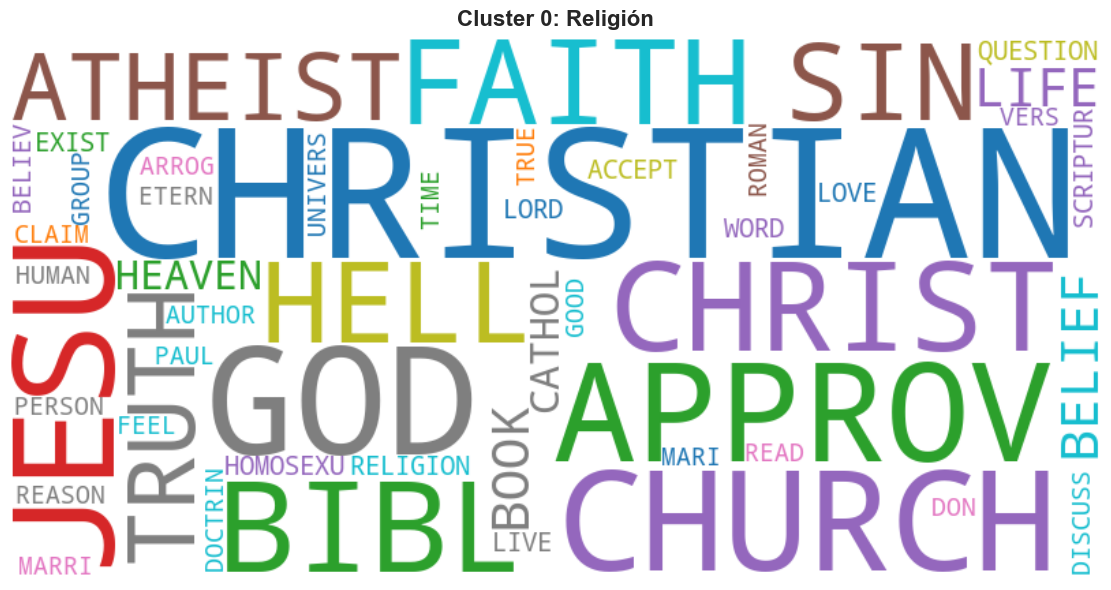

In [86]:
k = 0
word_freq = cluster_tfidf.loc[k].sort_values(ascending=False)
word_freq = word_freq[word_freq > 0].to_dict()

wc = WordCloud(
    width=800, height=400,
    background_color='white',
    max_words=50,
    colormap='tab10'
).generate_from_frequencies(word_freq)

fig, ax = plt.subplots(figsize=(12, 6))
ax.imshow(wc, interpolation='bilinear')
ax.axis('off')
ax.set_title(f'Cluster {k}: {diccionario_temas[k]}', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

**Cluster 0 - Religión**: dominado por términos como CHRISTIAN, CHURCH, 
  GOD, CHRIST, FAITH y BIBL. También aparecen palabras relacionadas con 
  el debate religioso como ATHEIST y APPROV.

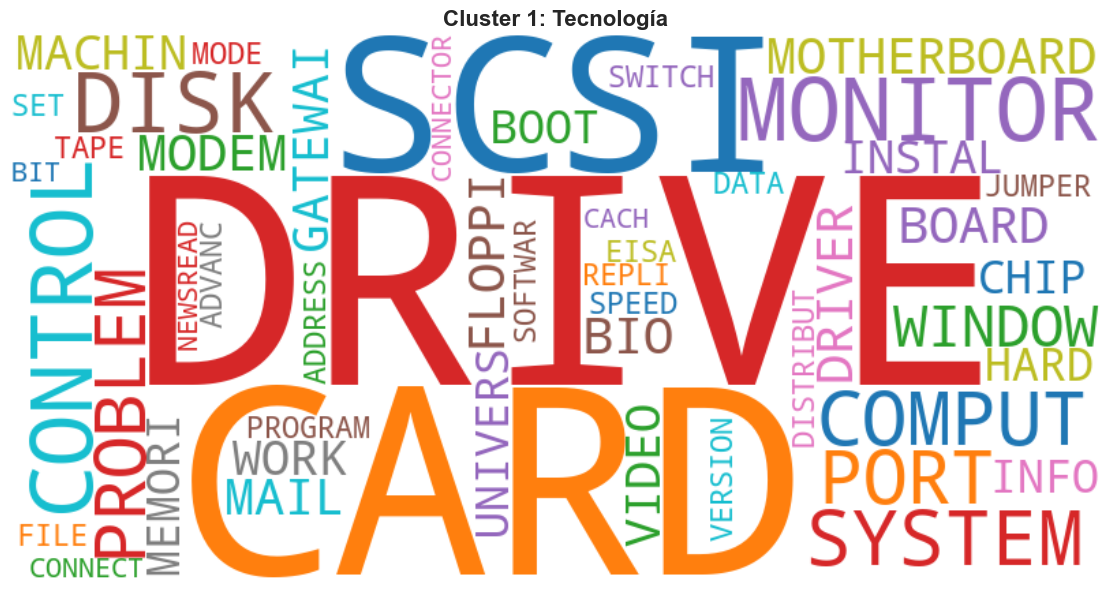

In [87]:
k = 1
word_freq = cluster_tfidf.loc[k].sort_values(ascending=False)
word_freq = word_freq[word_freq > 0].to_dict()

wc = WordCloud(
    width=800, height=400,
    background_color='white',
    max_words=50,
    colormap='tab10'
).generate_from_frequencies(word_freq)

fig, ax = plt.subplots(figsize=(12, 6))
ax.imshow(wc, interpolation='bilinear')
ax.axis('off')
ax.set_title(f'Cluster {k}: {diccionario_temas[k]}', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

**Cluster 1 - Tecnología**: liderado por DRIVE, CARD, SCSI y MONITOR, 
  con vocabulario claramente orientado a hardware informático: DISK, 
  CONTROL, COMPUT, MEMORY y MOTHERBOARD.

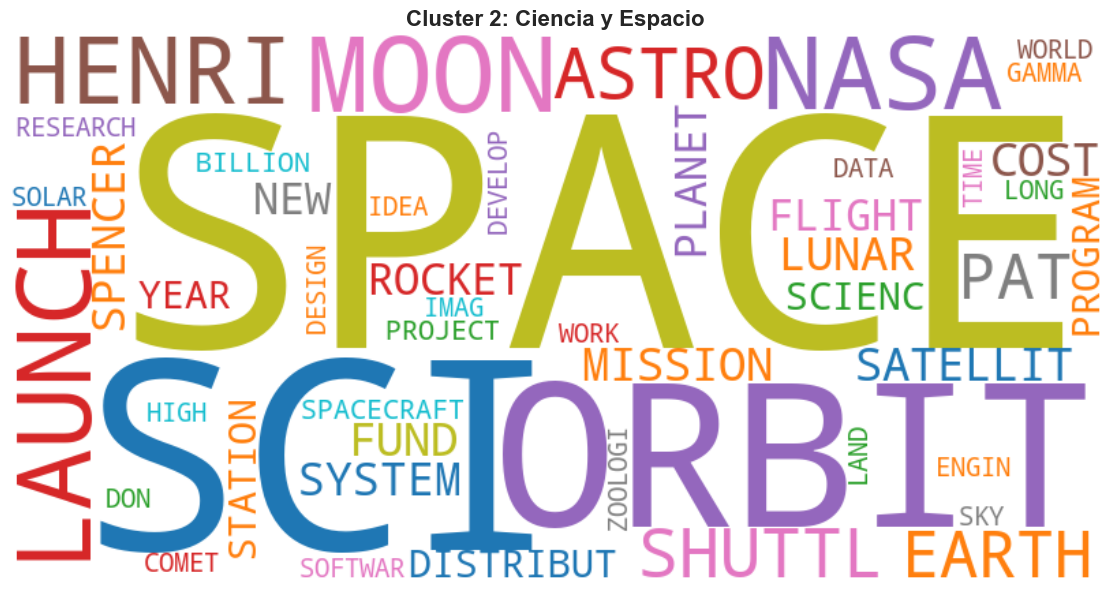

In [88]:
k = 2
word_freq = cluster_tfidf.loc[k].sort_values(ascending=False)
word_freq = word_freq[word_freq > 0].to_dict()

wc = WordCloud(
    width=800, height=400,
    background_color='white',
    max_words=50,
    colormap='tab10'
).generate_from_frequencies(word_freq)

fig, ax = plt.subplots(figsize=(12, 6))
ax.imshow(wc, interpolation='bilinear')
ax.axis('off')
ax.set_title(f'Cluster {k}: {diccionario_temas[k]}', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

**Cluster 2 - Ciencia y Espacio**: encabezado por SPACE, ORBIT, LAUNCH 
  y MOON, con términos propios de la exploración espacial como NASA, 
  SHUTTLE, SATELLITE y ROCKET.

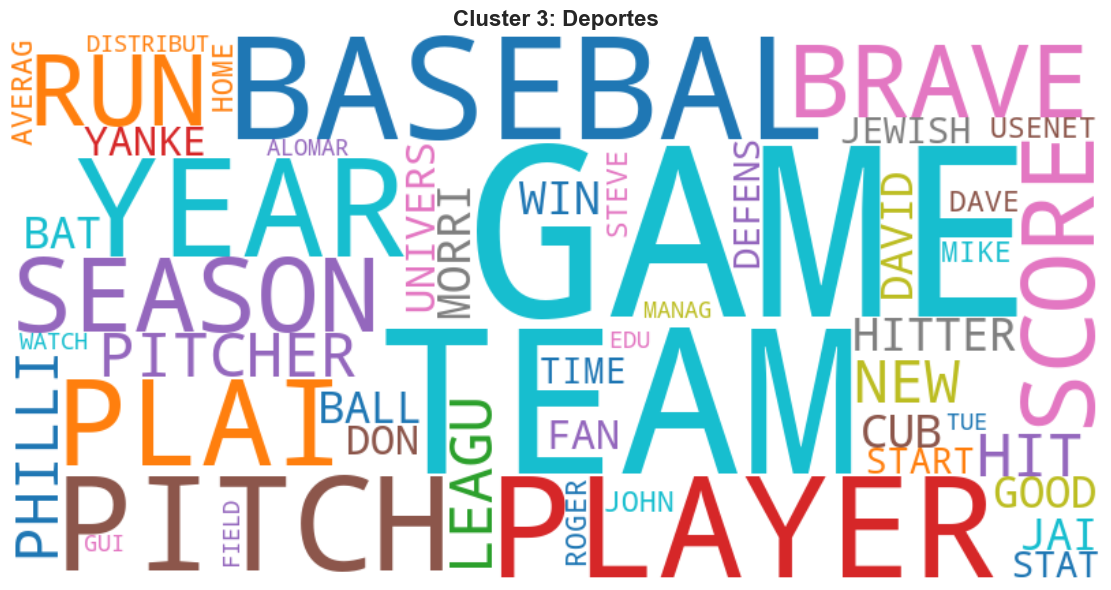

In [89]:
k = 3
word_freq = cluster_tfidf.loc[k].sort_values(ascending=False)
word_freq = word_freq[word_freq > 0].to_dict()

wc = WordCloud(
    width=800, height=400,
    background_color='white',
    max_words=50,
    colormap='tab10'
).generate_from_frequencies(word_freq)

fig, ax = plt.subplots(figsize=(12, 6))
ax.imshow(wc, interpolation='bilinear')
ax.axis('off')
ax.set_title(f'Cluster {k}: {diccionario_temas[k]}', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

- **Cluster 3 - Deportes**: dominado por GAME, BASEBALL, TEAM y PLAYER, 
  con vocabulario específico del béisbol como PITCH, HITTER, SEASON y 
  SCORE.